In [1]:
%pip install -q ipywidgets ipympl statsmodels pandas numpy matplotlib

%matplotlib widget

!jupyter nbextension enable --py widgetsnbextension --sys-prefix


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
usage: jupyter [-h] [--version] [--config-dir] [--data-dir] [--runtime-dir]
               [--paths] [--json] [--debug]
               [subcommand]

Jupyter: Interactive Computing

positional arguments:
  subcommand     the subcommand to launch

options:
  -h, --help     show this help message and exit
  --version      show the versions of core jupyter packages and exit
  --config-dir   show Jupyter config dir
  --data-dir     show Jupyter data dir
  --runtime-dir  show Jupyter runtime dir
  --paths        show all Jupyter paths. Add --json for machine-readable
                 format.
  --json         output paths as machine-readable json
  --debug        output debug information about paths

Available subcommands: builder dejavu events execute kernel kernelspec lab
labextension labhub migrate nbconvert run ser

In [2]:
%pip install -q ipywidgets ipympl statsmodels pandas numpy matplotlib

%matplotlib widget



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import asyncio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display

In [4]:
class MonitoringSimulator:

    def __init__(
        self,
        samples_per_period=20,
        min_arrived_to_train=15,
        missing_data_prob=0.10,
        train_failure_prob=0.10,
        delay_min=0.0,
        delay_max=1.0,
        noise_std=1.0,
        drift_amplitude=(2.0, 1.5, 1.0, 0.5),
        drift_phase=(0.0, 0.7, 1.4, 2.1),
        drift_period=60.0,
        random_seed=42,
    ):
        self.samples_per_period = int(samples_per_period)
        self.min_arrived_to_train = int(min_arrived_to_train)
        self.missing_data_prob = float(missing_data_prob)
        self.train_failure_prob = float(train_failure_prob)
        self.delay_min = float(delay_min)
        self.delay_max = float(delay_max)
        self.noise_std = float(noise_std)

        self.drift_amplitude = np.array(
            drift_amplitude,
            dtype=float
        )

        self.drift_phase = np.array(
            drift_phase,
            dtype=float
        )

        self.drift_period = float(drift_period)

        self.rng = np.random.default_rng(random_seed)

        self.reset()

    def reset(self):
        self.t = 0
        self.batch_idx = 0

        self.raw_buffer = []
        self.train_buffer = []
        self.arrival_flags = []

        self.batch_arrival_counts = []
        self.batch_missing_counts = []

        self.train_failure_history = []
        self.training_attempt_history = []
        self.training_success_history = []

        self.model = None

        self.model_info = {
            "message": "No model yet",
            "trained": False,
            "train_failure": False,
            "arrived_in_batch": 0,
            "missing_in_batch": 0,
        }

    def true_coeffs(self, t):
        omega = 2.0 * np.pi / self.drift_period

        return (
            self.drift_amplitude
            * np.sin(omega * t + self.drift_phase)
        )

    def generate_features(self):
        return self.rng.normal(
            0,
            1,
            size=3
        )

    def generate_target(self, x, t):
        b0, b1, b2, b3 = self.true_coeffs(t)

        y = (
            b0
            + b1 * x[0]
            + b2 * x[1]
            + b3 * x[2]
            + self.rng.normal(0, self.noise_std)
        )

        return float(y)

    def predict_one(self, x):

        if self.model is None:
            return None

        beta = self.model

        return float(
            beta[0]
            + beta[1] * x[0]
            + beta[2] * x[1]
            + beta[3] * x[2]
        )

    def maybe_train(self):

        batch_arrived = self.arrival_flags.count(1)
        batch_missing = self.arrival_flags.count(0)

        self.batch_arrival_counts.append(batch_arrived)
        self.batch_missing_counts.append(batch_missing)

        train_attempted = 0
        train_failure = 0
        train_success = 0

        if batch_arrived < self.min_arrived_to_train:

            message = (
                f"Skipped training: only "
                f"{batch_arrived}/{self.samples_per_period} "
                f"arrived; need at least "
                f"{self.min_arrived_to_train}."
            )

        else:

            train_attempted = 1

            if self.rng.random() < self.train_failure_prob:

                train_failure = 1

                message = (
                    "Training failed: "
                    "simulated training failure."
                )

            else:

                recent_rows = (
                    self.train_buffer[-batch_arrived:]
                )

                df = pd.DataFrame(
                    recent_rows,
                    columns=["X1", "X2", "X3", "Y"]
                )

                X = df[
                    ["X1", "X2", "X3"]
                ].to_numpy()

                y = df["Y"].to_numpy()

                X_design = np.column_stack(
                    [
                        np.ones(len(X)),
                        X
                    ]
                )

                beta, *_ = np.linalg.lstsq(
                    X_design,
                    y,
                    rcond=None
                )

                self.model = beta

                train_success = 1

                message = (
                    f"Trained successfully on "
                    f"{batch_arrived} arrived samples."
                )

        self.training_attempt_history.append(
            train_attempted
        )

        self.train_failure_history.append(
            train_failure
        )

        self.training_success_history.append(
            train_success
        )

        self.model_info = {
            "message": message,
            "trained": bool(train_success),
            "train_failure": bool(train_failure),
            "arrived_in_batch": batch_arrived,
            "missing_in_batch": batch_missing,
        }

    def step(self):

        delay = self.rng.uniform(
            self.delay_min,
            self.delay_max
        )

        arrived = int(
            self.rng.random()
            >= self.missing_data_prob
        )

        x = self.generate_features()

        y_true = self.generate_target(
            x,
            self.t
        )

        y_pred = None
        abs_error = None

        if arrived:

            self.train_buffer.append(
                [
                    x[0],
                    x[1],
                    x[2],
                    y_true
                ]
            )

            if self.model is not None:

                y_pred = self.predict_one(x)

                abs_error = abs(
                    y_true - y_pred
                )

        record = {
            "t": self.t,
            "arrived": arrived,
            "X1": x[0],
            "X2": x[1],
            "X3": x[2],
            "Y": y_true,
            "Y_pred": y_pred,
            "abs_error": abs_error,
            "delay": delay,
        }

        self.raw_buffer.append(record)

        self.arrival_flags.append(arrived)

        end_of_period = (
            (self.t + 1)
            % self.samples_per_period
            == 0
        )

        if end_of_period:

            self.maybe_train()

            self.batch_idx += 1

            self.arrival_flags = []

        self.t += 1

        return (
            record,
            end_of_period,
            delay
        )

    def last_batch_errors(self):

        recent = self.raw_buffer[
            -self.samples_per_period:
        ]

        return [
            r["abs_error"]
            for r in recent
            if r["abs_error"] is not None
        ]

In [5]:
samples_per_period_w = widgets.IntSlider(
    value=20,
    min=5,
    max=50,
    step=1,
    description="Period"
)

min_arrived_w = widgets.IntSlider(
    value=15,
    min=1,
    max=50,
    step=1,
    description="Min arrived"
)

missing_prob_w = widgets.FloatSlider(
    value=0.10,
    min=0.0,
    max=1.0,
    step=0.01,
    description="Missing p"
)

train_fail_prob_w = widgets.FloatSlider(
    value=0.10,
    min=0.0,
    max=1.0,
    step=0.01,
    description="Train fail p"
)

noise_std_w = widgets.FloatSlider(
    value=1.0,
    min=0.0,
    max=5.0,
    step=0.1,
    description="Noise sd"
)

drift_period_w = widgets.FloatSlider(
    value=60.0,
    min=10.0,
    max=200.0,
    step=1.0,
    description="Drift period"
)

amp0_w = widgets.FloatSlider(
    value=2.0,
    min=0.0,
    max=10.0,
    step=0.1,
    description="A0"
)

amp1_w = widgets.FloatSlider(
    value=1.5,
    min=0.0,
    max=10.0,
    step=0.1,
    description="A1"
)

amp2_w = widgets.FloatSlider(
    value=1.0,
    min=0.0,
    max=10.0,
    step=0.1,
    description="A2"
)

amp3_w = widgets.FloatSlider(
    value=0.5,
    min=0.0,
    max=10.0,
    step=0.1,
    description="A3"
)

phase0_w = widgets.FloatSlider(
    value=0.0,
    min=0.0,
    max=6.28,
    step=0.01,
    description="P0"
)

phase1_w = widgets.FloatSlider(
    value=0.7,
    min=0.0,
    max=6.28,
    step=0.01,
    description="P1"
)

phase2_w = widgets.FloatSlider(
    value=1.4,
    min=0.0,
    max=6.28,
    step=0.01,
    description="P2"
)

phase3_w = widgets.FloatSlider(
    value=2.1,
    min=0.0,
    max=6.28,
    step=0.01,
    description="P3"
)

start_btn = widgets.Button(
    description="Start",
    button_style="success"
)

pause_btn = widgets.Button(
    description="Pause",
    button_style="warning"
)

restart_btn = widgets.Button(
    description="Restart",
    button_style="danger"
)

status_html = widgets.HTML()

In [6]:
def make_simulator():

    period = int(
        samples_per_period_w.value
    )

    min_arrived = min(
        int(min_arrived_w.value),
        period
    )

    return MonitoringSimulator(
        samples_per_period=period,
        min_arrived_to_train=min_arrived,
        missing_data_prob=missing_prob_w.value,
        train_failure_prob=train_fail_prob_w.value,
        noise_std=noise_std_w.value,
        drift_amplitude=(
            amp0_w.value,
            amp1_w.value,
            amp2_w.value,
            amp3_w.value
        ),
        drift_phase=(
            phase0_w.value,
            phase1_w.value,
            phase2_w.value,
            phase3_w.value
        ),
        drift_period=drift_period_w.value,
        random_seed=np.random.randint(
            0,
            1_000_000
        ),
    )


sim = make_simulator()

running = False
task = None

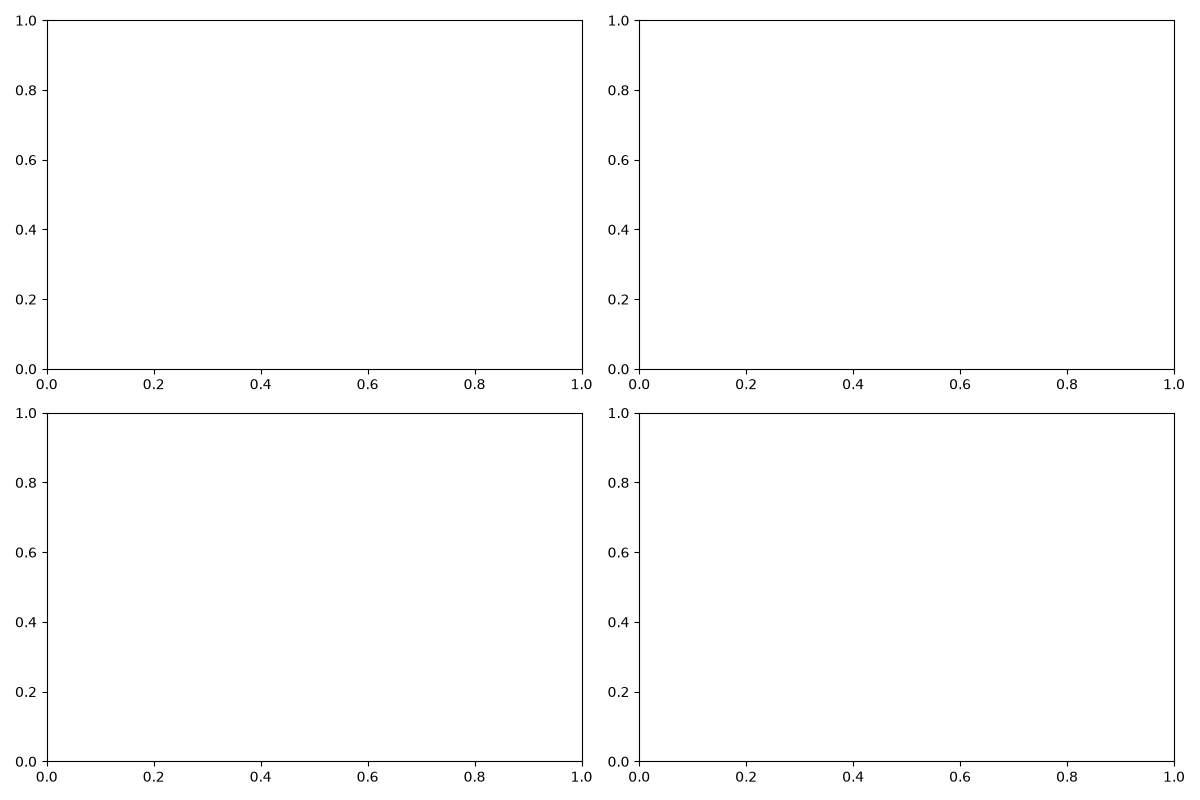

In [7]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8)
)

ax_err, ax_arr, ax_fail, ax_text = axes.flatten()

try:
    fig.canvas.header_visible = False
except Exception:
    pass

plt.tight_layout()

In [8]:
def refresh_dashboard():

    ax_err.clear()
    ax_arr.clear()
    ax_fail.clear()
    ax_text.clear()

    errors = sim.last_batch_errors()

    # -------------------------
    # Prediction error chart
    # -------------------------

    if len(errors) > 0:

        ax_err.hist(
            errors,
            bins=min(
                10,
                max(1, len(errors))
            ),
            color="steelblue",
            edgecolor="white"
        )

    else:

        ax_err.text(
            0.5,
            0.5,
            "No prediction errors yet\n"
            "model has not scored enough samples",
            ha="center",
            va="center"
        )

    ax_err.set_title(
        "Absolute error histogram, recent period"
    )

    ax_err.set_xlabel("|Y - Ŷ|")
    ax_err.set_ylabel("Count")

    # -------------------------
    # Data arrival chart
    # -------------------------

    if len(sim.batch_arrival_counts) > 0:

        arrived = sim.batch_arrival_counts[-1]
        missing = sim.batch_missing_counts[-1]

        ax_arr.bar(
            ["Arrived", "Missing"],
            [arrived, missing],
            color=[
                "seagreen",
                "crimson"
            ]
        )

        ax_arr.set_ylim(
            0,
            sim.samples_per_period
        )

        ax_arr.set_ylabel("Count")

        ax_arr.set_title(
            "Data arrival status, last completed period"
        )

    else:

        current_arrived = (
            sim.arrival_flags.count(1)
        )

        current_missing = (
            sim.arrival_flags.count(0)
        )

        ax_arr.bar(
            [
                "Arrived so far",
                "Missing so far"
            ],
            [
                current_arrived,
                current_missing
            ],
            color=[
                "seagreen",
                "crimson"
            ]
        )

        ax_arr.set_ylim(
            0,
            sim.samples_per_period
        )

        ax_arr.set_title(
            "Data arrival status, current period"
        )

        ax_arr.set_ylabel("Count")

    # -------------------------
    # Training failures
    # -------------------------

    if len(sim.train_failure_history) > 0:

        recent_failures = (
            sim.train_failure_history[-20:]
        )

        x = np.arange(
            1,
            len(recent_failures) + 1
        )

        ax_fail.bar(
            x,
            recent_failures,
            color="darkorange"
        )

        ax_fail.set_ylim(0, 1.2)

        ax_fail.set_yticks([0, 1])

        ax_fail.set_xlabel(
            "Recent completed period"
        )

        ax_fail.set_ylabel("Failed?")

        ax_fail.set_title(
            "Training failures"
        )

    else:

        ax_fail.text(
            0.5,
            0.5,
            "No completed training checks yet",
            ha="center",
            va="center"
        )

        ax_fail.set_title(
            "Training failures"
        )

    # -------------------------
    # Status text
    # -------------------------

    ax_text.axis("off")

    coeffs = sim.true_coeffs(sim.t)

    if sim.model is None:

        model_text = "None yet"

    else:

        model_text = np.array2string(
            sim.model,
            precision=3,
            suppress_small=True
        )

    status_text = (
        f"Running: {running}\n"
        f"Time step: {sim.t}\n"
        f"Completed periods: {sim.batch_idx}\n"
        f"Current period progress: "
        f"{len(sim.arrival_flags)} / "
        f"{sim.samples_per_period}\n\n"

        f"Latest status:\n"
        f"{sim.model_info.get('message', '')}\n\n"

        f"Current true coefficients:\n"
        f"b0={coeffs[0]: .3f}\n"
        f"b1={coeffs[1]: .3f}\n"
        f"b2={coeffs[2]: .3f}\n"
        f"b3={coeffs[3]: .3f}\n\n"

        f"Current fitted model:\n"
        f"{model_text}"
    )

    ax_text.text(
        0.02,
        0.98,
        status_text,
        va="top",
        ha="left",
        family="monospace",
        fontsize=10
    )

    status_html.value = (
        f"<b>Running:</b> {running} &nbsp; "
        f"<b>Time step:</b> {sim.t} &nbsp; "
        f"<b>Completed periods:</b> "
        f"{sim.batch_idx} &nbsp; "
        f"<b>Latest:</b> "
        f"{sim.model_info.get('message', '')}"
    )

    fig.tight_layout()

    fig.canvas.draw_idle()

In [9]:
async def simulation_loop():

    global running

    while running:

        record, end_of_period, delay = (
            sim.step()
        )

        refresh_dashboard()

        await asyncio.sleep(delay)


def start_clicked(_):

    global running, task

    if running:
        return

    running = True

    refresh_dashboard()

    task = asyncio.create_task(
        simulation_loop()
    )


def pause_clicked(_):

    global running

    running = False

    refresh_dashboard()


def restart_clicked(_):

    global sim, running, task

    running = False

    if task is not None:

        task.cancel()

        task = None

    sim = make_simulator()

    running = True

    refresh_dashboard()

    task = asyncio.create_task(
        simulation_loop()
    )


start_btn.on_click(start_clicked)

pause_btn.on_click(pause_clicked)

restart_btn.on_click(restart_clicked)

HTML(value='')

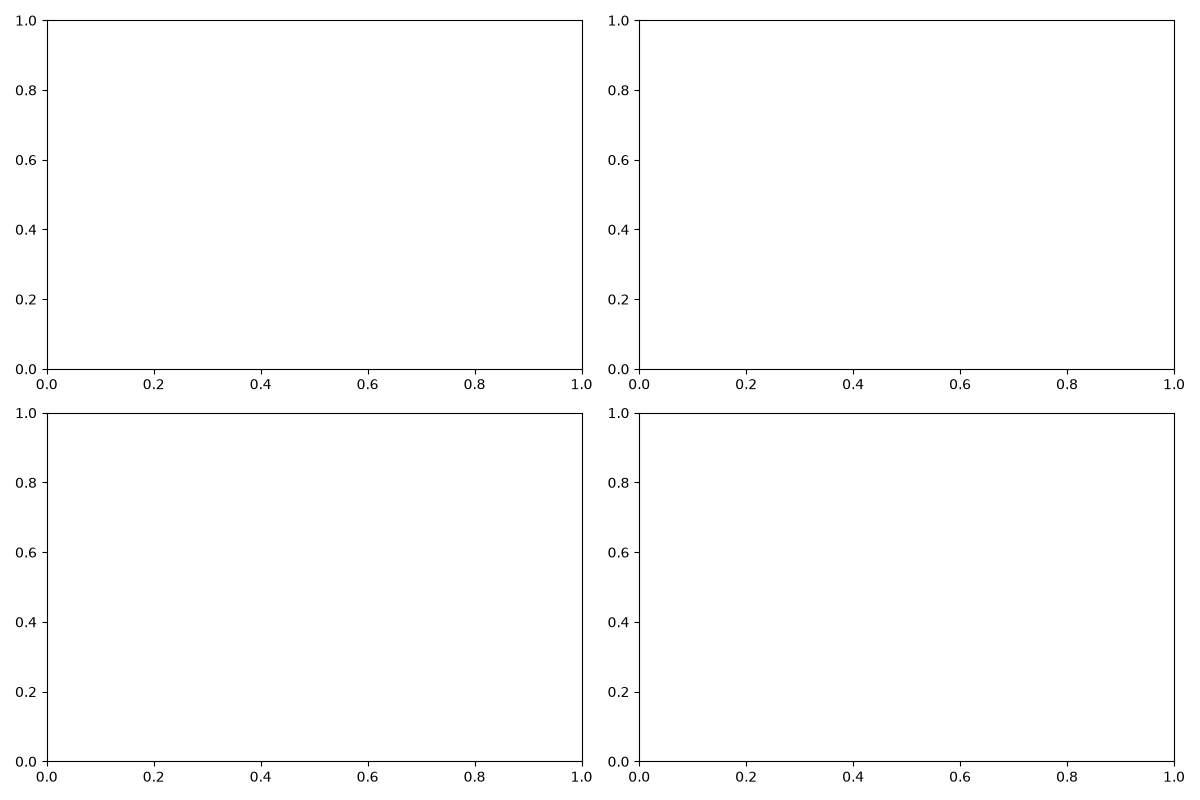

In [10]:
controls = widgets.VBox(
    [
        widgets.HBox(
            [
                start_btn,
                pause_btn,
                restart_btn
            ]
        ),

        widgets.HBox(
            [
                samples_per_period_w,
                min_arrived_w
            ]
        ),

        widgets.HBox(
            [
                missing_prob_w,
                train_fail_prob_w
            ]
        ),

        widgets.HBox(
            [
                noise_std_w,
                drift_period_w
            ]
        ),

        widgets.HBox(
            [
                amp0_w,
                amp1_w,
                amp2_w,
                amp3_w
            ]
        ),

        widgets.HBox(
            [
                phase0_w,
                phase1_w,
                phase2_w,
                phase3_w
            ]
        ),
    ]
)

display(controls)

display(status_html)

display(fig.canvas)

refresh_dashboard()

HTML(value='')

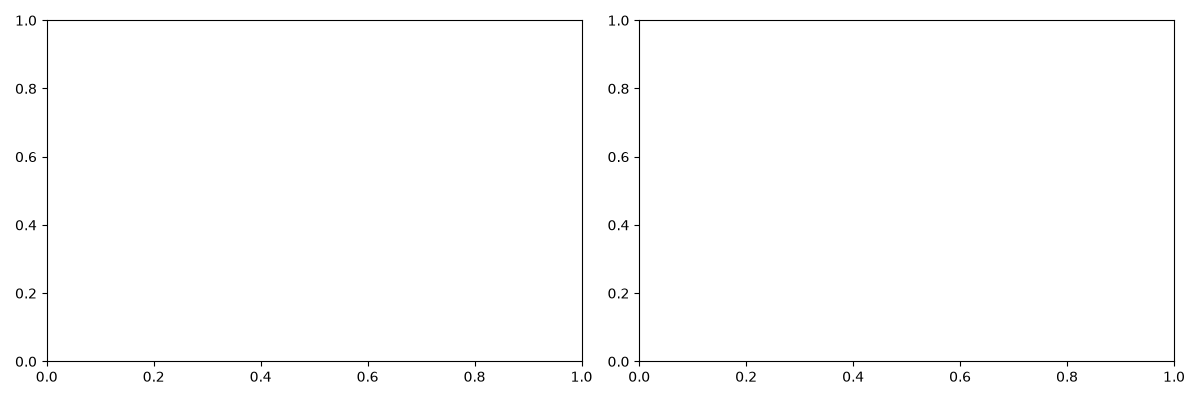

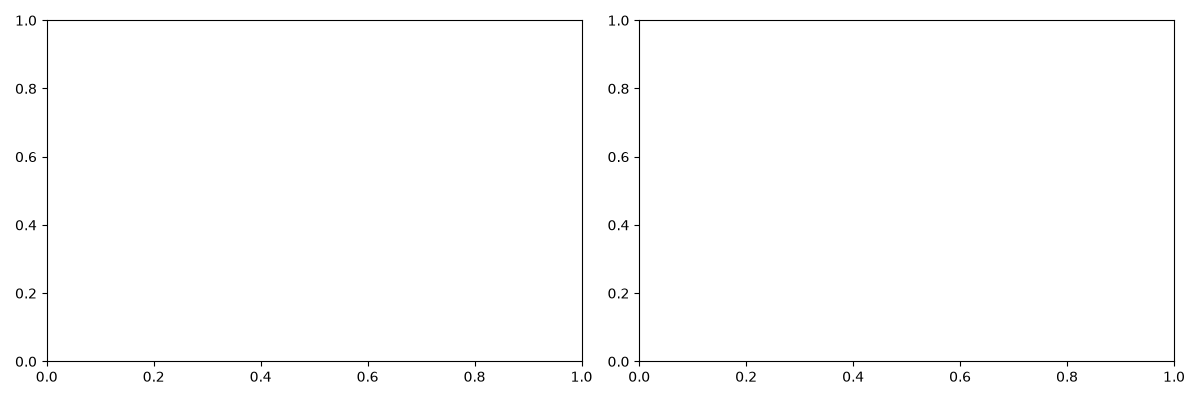

In [12]:
# Cell 1 - Imports

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

rng = np.random.default_rng(42)

# Original distribution that represents training data
reference = rng.normal(loc=0, scale=1, size=1000)

psi_history = []
batch_number = 0

# Controls
mean_drift = widgets.FloatSlider(
    value=0.0, min=0.0, max=2.0, step=0.1,
    description="Mean drift"
)

variance_drift = widgets.FloatSlider(
    value=0.0, min=0.0, max=1.5, step=0.1,
    description="Variance drift"
)

next_button = widgets.Button(
    description="Next Batch",
    button_style="success"
)

reset_button = widgets.Button(
    description="Reset",
    button_style="danger"
)

status = widgets.HTML()


# Cell 2 - PSI calculation

def calculate_psi(reference_data, current_data, bins=10):

    # Use percentiles of reference distribution to make bins
    breakpoints = np.percentile(
        reference_data,
        np.linspace(0, 100, bins + 1)
    )

    # Make sure outside values still fall into a bin
    breakpoints[0] = -np.inf
    breakpoints[-1] = np.inf

    reference_counts, _ = np.histogram(
        reference_data, bins=breakpoints
    )

    current_counts, _ = np.histogram(
        current_data, bins=breakpoints
    )

    reference_pct = reference_counts / len(reference_data)
    current_pct = current_counts / len(current_data)

    # Prevent log(0)
    epsilon = 0.0001

    reference_pct = np.maximum(reference_pct, epsilon)
    current_pct = np.maximum(current_pct, epsilon)

    psi = np.sum(
        (current_pct - reference_pct) *
        np.log(current_pct / reference_pct)
    )

    return psi


# Cell 3 - Drift interpretation

def drift_status(psi):

    if psi < 0.10:
        return "STABLE", "green"

    elif psi < 0.25:
        return "WARNING", "orange"

    else:
        return "DRIFT ALERT", "red"


# Cell 4 - Create dashboard

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax_distribution = axes[0]
ax_psi = axes[1]

plt.tight_layout()


def update_dashboard(current):

    ax_distribution.clear()
    ax_psi.clear()

    # Distribution comparison
    ax_distribution.hist(
        reference,
        bins=25,
        alpha=0.5,
        label="Reference"
    )

    ax_distribution.hist(
        current,
        bins=25,
        alpha=0.5,
        label="Current"
    )

    ax_distribution.set_title(
        "Reference vs Current Distribution"
    )

    ax_distribution.set_xlabel("Feature value")
    ax_distribution.set_ylabel("Count")
    ax_distribution.legend()

    # PSI history
    if len(psi_history) > 0:

        x = np.arange(1, len(psi_history) + 1)

        ax_psi.plot(
            x,
            psi_history,
            marker="o"
        )

        ax_psi.axhline(
            0.10,
            color="orange",
            linestyle="--",
            label="Warning"
        )

        ax_psi.axhline(
            0.25,
            color="red",
            linestyle="--",
            label="Drift Alert"
        )

        ax_psi.set_xlabel("Production Batch")
        ax_psi.set_ylabel("PSI")
        ax_psi.set_title("Distribution Drift Over Time")
        ax_psi.legend()

    fig.tight_layout()
    fig.canvas.draw_idle()


# Cell 5 - Generate production batches

def next_batch(_):

    global batch_number

    batch_number += 1

    # Production distribution changes based on sliders
    new_mean = mean_drift.value
    new_std = 1 + variance_drift.value

    current = rng.normal(
        loc=new_mean,
        scale=new_std,
        size=500
    )

    psi = calculate_psi(reference, current)

    psi_history.append(psi)

    label, color = drift_status(psi)

    status.value = (
        f"<h3 style='color:{color}'>"
        f"Batch {batch_number}: {label}</h3>"
        f"<b>PSI:</b> {psi:.3f}<br>"
        f"<b>Current mean:</b> {current.mean():.3f}<br>"
        f"<b>Current standard deviation:</b> "
        f"{current.std():.3f}"
    )

    update_dashboard(current)


# Cell 6 - Reset

def reset(_):

    global batch_number

    batch_number = 0
    psi_history.clear()

    status.value = "<b>Monitor reset.</b>"

    ax_distribution.clear()
    ax_psi.clear()

    ax_distribution.set_title(
        "Reference vs Current Distribution"
    )

    ax_psi.set_title(
        "Distribution Drift Over Time"
    )

    fig.canvas.draw_idle()


next_button.on_click(next_batch)
reset_button.on_click(reset)


# Cell 7 - Display controls

controls = widgets.VBox([
    widgets.HBox([next_button, reset_button]),
    mean_drift,
    variance_drift
])

display(controls)
display(status)
display(fig.canvas)